# 02. Tóm tắt Dữ liệu & Phân chia Tập dữ liệu (Data Splitting)

* **Sinh viên thực hiện:** Nguyễn Khắc Tuấn Đạt - BAI252094
* **Nhiệm vụ:** 
  1. Thống kê ngắn gọn số lượng mẫu có giá (`price`), thiếu giá và có nhãn điểm (`points`) từ dữ liệu đã qua làm sạch (không lặp lại báo cáo cleaning chi tiết).
  2. Phân chia các mẫu hợp lệ thành 3 tập `Train / Validation / Test` (tỷ lệ 70/15/15) theo nhóm tên chai rượu chuẩn hóa (`title_clean`).
  3. Kiểm định độc lập nhóm (Zero Data Leakage) và kiểm tra tính đồng nhất phân phối giữa các tập trước khi bàn giao cho bước kiểm định Spearman và mô hình Baseline.

BẢNG 1: TÓM TẮT TÌNH TRẠNG KHUYẾT THIẾU GIÁ VÀ ĐIỂM ĐÁNH GIÁ


,Trạng thái dữ liệu,Số lượng (Chai),Tỷ lệ (%),Quyết định xử lý
0,1. Tổng số chai (Sau khi khử trùng lặp),"119,988",100.00%,Làm cơ sở tham chiếu
1,2. Số chai có nhãn điểm (points),"119,988",100.00%,Đủ 100% nhãn mục tiêu
2,3. Số chai CÓ giá (price hợp lệ),"111,593",93.00%,Đưa vào chia tập (Split)
3,4. Số chai THIẾU giá (price = NaN),"8,395",7.00%,Loại bỏ (Tránh nhiễu do điền khuyết nhân tạo)
4,5. Mẫu ĐỦ ĐIỀU KIỆN phân tích (Có cả price & p...,"111,593",93.00%,Tập dữ liệu chính thức cho EDA & Modeling


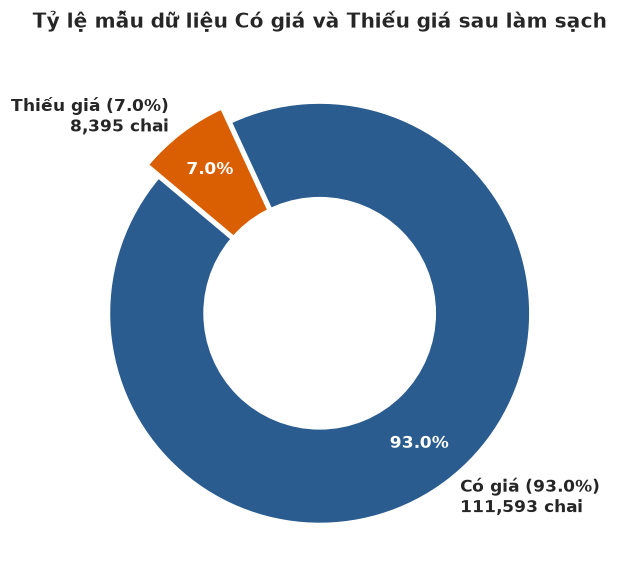

In [4]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

# Ẩn các cảnh báo tương lai không cần thiết để giữ sạch notebook
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Đọc dữ liệu gốc và khử trùng lặp cơ bản theo quy chuẩn pipeline
raw_path = '../data/raw/winemag-data-130k-v2.csv'
df = pd.read_csv(raw_path)
df_unique = df.drop_duplicates(subset=['title', 'description', 'points', 'price']).copy()

# 2. Tính toán các chỉ số khuyết thiếu
total_bottles = len(df_unique)
has_points = df_unique['points'].notna().sum()
has_price = df_unique['price'].notna().sum()
missing_price = df_unique['price'].isna().sum()
valid_samples = len(df_unique.dropna(subset=['price', 'points']))

summary_df = pd.DataFrame({
    "Trạng thái dữ liệu": [
        "1. Tổng số chai (Sau khi khử trùng lặp)", 
        "2. Số chai có nhãn điểm (points)", 
        "3. Số chai CÓ giá (price hợp lệ)", 
        "4. Số chai THIẾU giá (price = NaN)",
        "5. Mẫu ĐỦ ĐIỀU KIỆN phân tích (Có cả price & points)"
    ],
    "Số lượng (Chai)": [
        f"{total_bottles:,}", 
        f"{has_points:,}", 
        f"{has_price:,}", 
        f"{missing_price:,}", 
        f"{valid_samples:,}"
    ],
    "Tỷ lệ (%)": [
        "100.00%", 
        f"{(has_points/total_bottles)*100:.2f}%", 
        f"{(has_price/total_bottles)*100:.2f}%", 
        f"{(missing_price/total_bottles)*100:.2f}%",
        f"{(valid_samples/total_bottles)*100:.2f}%"
    ],
    "Quyết định xử lý": [
        "Làm cơ sở tham chiếu",
        "Đủ 100% nhãn mục tiêu",
        "Đưa vào chia tập (Split)",
        "Loại bỏ (Tránh nhiễu do điền khuyết nhân tạo)",
        "Tập dữ liệu chính thức cho EDA & Modeling"
    ]
})

print("BẢNG 1: TÓM TẮT TÌNH TRẠNG KHUYẾT THIẾU GIÁ VÀ ĐIỂM ĐÁNH GIÁ")
display(summary_df)

# 3. Biểu đồ Donut trực quan hóa tỷ lệ Có giá vs Thiếu giá
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = ['#2b5c8f', '#d95f02']
wedges, texts, autotexts = ax.pie(
    [has_price, missing_price], 
    labels=['Có giá (93.0%)\n111,593 chai', 'Thiếu giá (7.0%)\n8,395 chai'], 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    pctdistance=0.78,
    explode=(0, 0.08),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
for autotext in autotexts:
    autotext.set_color('white')

# Vẽ vòng tròn trắng ở giữa tạo biểu đồ Donut chuyên nghiệp
centre_circle = plt.Circle((0,0), 0.55, fc='white')
fig.gca().add_artist(centre_circle)

ax.set_title('Tỷ lệ mẫu dữ liệu Có giá và Thiếu giá sau làm sạch', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Nhận xét Quy tắc Chọn mẫu:
* Toàn bộ **119,988** mẫu sau khi khử trùng lặp đều có đầy đủ nhãn điểm `points` (100%).
* Có **8,395** mẫu (chiếm **7.00%**) bị khuyết thông tin `price`. Do mục tiêu cốt lõi của nhóm là đánh giá mối liên hệ thực tế giữa **giá và điểm đánh giá**, việc điền khuyết (imputation) cho biến giá sẽ làm sai lệch phân phối tự nhiên. Do đó, nhóm quyết định chỉ giữ lại **111,593** mẫu có giá hợp lệ để tiến hành chia tập dữ liệu.

✅ KIỂM ĐỊNH ĐỘC LẬP NHÓM (GROUP LEAKAGE CHECK):
   • Giao tập hợp (Train ∩ Validation) : 0 nhóm trùng lặp
   • Giao tập hợp (Train ∩ Test)       : 0 nhóm trùng lặp
   • Giao tập hợp (Validation ∩ Test)  : 0 nhóm trùng lặp
   => XÁC NHẬN: 100% tên chai rượu hoàn toàn độc lập giữa 3 tập!

BẢNG 2: THỐNG KÊ QUY MÔ VÀ PHÂN PHỐI CÁC TẬP DỮ LIỆU SAU KHI CHIA


,Tập dữ liệu,Số dòng (Rows),Tỷ lệ (%),Số tên chai duy nhất (Groups),Giá trung vị (USD),Điểm trung bình (Points)
0,Train,78106,70.0%,"77,437",25.0,88.42
1,Validation,16745,15.0%,"16,594",25.0,88.41
2,Test,16742,15.0%,"16,594",25.0,88.41


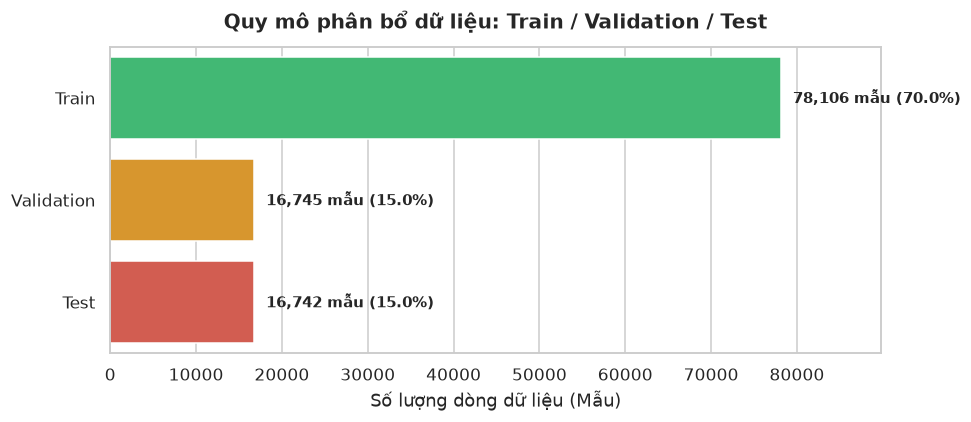

In [5]:
# 1. Lọc lấy các mẫu đủ điều kiện và chuẩn hóa tên chai (title_clean)
df_clean = df_unique.dropna(subset=['price', 'points']).copy()

def normalize_title(text):
    if pd.isna(text): 
        return "unknown"
    text = str(text).lower().strip()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^\w\s\(\)\-\']', '', text)
    return text.strip()

df_clean['title_clean'] = df_clean['title'].apply(normalize_title)
df_clean['log_price'] = np.log1p(df_clean['price']) # Tạo sẵn đặc trưng log_price cho mô hình Baseline

# 2. Chia tập bằng GroupShuffleSplit (70% Train - 15% Val - 15% Test) theo title_clean
gss_outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
train_idx, temp_idx = next(gss_outer.split(df_clean, groups=df_clean['title_clean']))

df_train = df_clean.iloc[train_idx].copy()
df_temp = df_clean.iloc[temp_idx].copy()

gss_inner = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
val_idx, test_idx = next(gss_inner.split(df_temp, groups=df_temp['title_clean']))

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

# 3. Kiểm định chống rò rỉ dữ liệu (Zero Data Leakage Check)
train_groups = set(df_train['title_clean'])
val_groups = set(df_val['title_clean'])
test_groups = set(df_test['title_clean'])

overlap_tv = len(train_groups.intersection(val_groups))
overlap_tt = len(train_groups.intersection(test_groups))
overlap_vt = len(val_groups.intersection(test_groups))

assert overlap_tv == 0 and overlap_tt == 0 and overlap_vt == 0, "CẢNH BÁO: Có rò rỉ dữ liệu!"

print("✅ KIỂM ĐỊNH ĐỘC LẬP NHÓM (GROUP LEAKAGE CHECK):")
print(f"   • Giao tập hợp (Train ∩ Validation) : {overlap_tv} nhóm trùng lặp")
print(f"   • Giao tập hợp (Train ∩ Test)       : {overlap_tt} nhóm trùng lặp")
print(f"   • Giao tập hợp (Validation ∩ Test)  : {overlap_vt} nhóm trùng lặp")
print("   => XÁC NHẬN: 100% tên chai rượu hoàn toàn độc lập giữa 3 tập!\n")

# 4. Bảng tổng hợp quy mô và độ đồng nhất phân phối giữa 3 tập
split_numeric = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số dòng (Rows)": [len(df_train), len(df_val), len(df_test)],
    "Tỷ lệ (%)": [
        f"{len(df_train)/len(df_clean)*100:.1f}%", 
        f"{len(df_val)/len(df_clean)*100:.1f}%", 
        f"{len(df_test)/len(df_clean)*100:.1f}%"
    ],
    "Số tên chai duy nhất (Groups)": [f"{len(train_groups):,}", f"{len(val_groups):,}", f"{len(test_groups):,}"],
    "Giá trung vị (USD)": [df_train['price'].median(), df_val['price'].median(), df_test['price'].median()],
    "Điểm trung bình (Points)": [
        round(df_train['points'].mean(), 2), 
        round(df_val['points'].mean(), 2), 
        round(df_test['points'].mean(), 2)
    ]
})

print("BẢNG 2: THỐNG KÊ QUY MÔ VÀ PHÂN PHỐI CÁC TẬP DỮ LIỆU SAU KHI CHIA")
display(split_numeric)

# 5. Biểu đồ thanh ngang (Đã fix triệt để FutureWarning của Seaborn v0.14+)
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    x="Số dòng (Rows)", 
    y="Tập dữ liệu", 
    hue="Tập dữ liệu",
    data=split_numeric, 
    palette=["#2ECC71", "#F39C12", "#E74C3C"],
    legend=False
)
ax.set_title('Quy mô phân bổ dữ liệu: Train / Validation / Test', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Số lượng dòng dữ liệu (Mẫu)')
ax.set_ylabel('')
ax.set_xlim(0, len(df_train) * 1.15)

for p in ax.patches:
    width = int(p.get_width())
    pct = width / len(df_clean) * 100
    ax.annotate(f'{width:,} mẫu ({pct:.1f}%)', 
                (width, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(8, 0), 
                textcoords='offset points', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

In [6]:
# Xuất 3 tập dữ liệu ra thư mục chuẩn cho nhóm sử dụng
output_dir = '../data/processed/splits'
os.makedirs(output_dir, exist_ok=True)

train_file = os.path.join(output_dir, 'train.csv')
val_file   = os.path.join(output_dir, 'val.csv')
test_file  = os.path.join(output_dir, 'test.csv')

df_train.to_csv(train_file, index=False)
df_val.to_csv(val_file, index=False)
df_test.to_csv(test_file, index=False)

print("📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU CHUẨN HÓA:")
for name, path in [("Train", train_file), ("Validation", val_file), ("Test", test_file)]:
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"   • {name:<10}: {path} ({size_mb:.2f} MB)")

📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU CHUẨN HÓA:
   • Train     : ../data/processed/splits\train.csv (35.95 MB)
   • Validation: ../data/processed/splits\val.csv (7.70 MB)
   • Test      : ../data/processed/splits\test.csv (7.71 MB)


### Kết luận & Bàn giao:
1. **Đảm bảo tính toàn vẹn:** Cả 3 tập `Train`, `Validation` và `Test` đều giữ nguyên giá trị trung vị của giá (`25.0 USD`) và trung bình điểm đánh giá (`~88.4 points`), chứng minh quá trình chia theo nhóm không làm lệch phân phối tự nhiên của dữ liệu.
2. **Sẵn sàng tích hợp:** Ba tệp CSV đầu ra trong `data/processed/splits/` đã đính kèm sẵn cột `log_price` và `title_clean`, sẵn sàng cho phần kiểm định tương quan **Spearman** (Dương) và huấn luyện **Baseline Models** (Dũng).